In [2]:
import pandas as pd
df = pd.read_csv("../data/raw/spotify-tracks-dataset.csv")
print(df.shape)
df.head()

(114000, 22)


,Unnamed: 0.1,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 22 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0.1      114000 non-null  int64  
 1   Unnamed: 0        114000 non-null  int64  
 2   track_id          114000 non-null  str    
 3   artists           113999 non-null  str    
 4   album_name        113999 non-null  str    
 5   track_name        113999 non-null  str    
 6   popularity        114000 non-null  int64  
 7   duration_ms       114000 non-null  int64  
 8   explicit          114000 non-null  bool   
 9   danceability      114000 non-null  float64
 10  energy            114000 non-null  float64
 11  key               114000 non-null  int64  
 12  loudness          114000 non-null  float64
 13  mode              114000 non-null  int64  
 14  speechiness       114000 non-null  float64
 15  acousticness      114000 non-null  float64
 16  instrumentalness  114000 non-nu

In [4]:
print(df["track_id"].duplicated().sum())

24259


In [5]:
features = ["danceability", "energy", "loudness", "speechiness",
            "acousticness", "instrumentalness", "valence", "tempo"]
df[features].describe()

,danceability,energy,loudness,speechiness,acousticness,instrumentalness,valence,tempo
count,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000
mean,0.566800,0.641383,-8.258960,0.084652,0.314910,0.156050,0.474068,122.147837
std,0.173542,0.251529,5.029337,0.105732,0.332523,0.309555,0.259261,29.978197
min,0.000000,0.000000,-49.531000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.456000,0.472000,-10.013000,0.035900,0.016900,0.000000,0.260000,99.218750
50%,0.580000,0.685000,-7.004000,0.048900,0.169000,0.000042,0.464000,122.017000
75%,0.695000,0.854000,-5.003000,0.084500,0.598000,0.049000,0.683000,140.071000
max,0.985000,1.000000,4.532000,0.965000,0.996000,1.000000,0.995000,243.372000


In [6]:
df["track_genre"].value_counts()

track_genre
acoustic       1000
afrobeat       1000
alt-rock       1000
alternative    1000
ambient        1000
               ... 
techno         1000
trance         1000
trip-hop       1000
turkish        1000
world-music    1000
Name: count, Length: 114, dtype: int64

In [7]:
df = df.drop(columns=["Unnamed: 0.1", "Unnamed: 0"])

exclude = ["comedy", "children", "kids", "disney", "sleep", "study",
           "opera", "new-age", "show-tunes", "romance", "sad"]
print([g for g in exclude if g not in df["track_genre"].unique()])  # should print []

df = df.dropna()
df = df[~df["track_genre"].isin(exclude)]
df = df.drop_duplicates(subset="track_id")
# Same song appears under different track_ids (remixes, re-releases, albums).
# Keep the most popular version of each title + main artist.
df["main_artist"] = df["artists"].str.split(";").str[0]
df = df.sort_values("popularity", ascending=False)
df = df.drop_duplicates(subset=["track_name", "main_artist"])
df = df[(df["tempo"] > 0)
        & (df["duration_ms"].between(120_000, 420_000))
        & (df["speechiness"] < 0.66)]
df = df.reset_index(drop=True)
print(df.shape)

[]
(65416, 21)


In [8]:
from sklearn.preprocessing import StandardScaler

FEATURES = ["energy", "valence", "tempo", "danceability",
            "loudness", "acousticness", "instrumentalness"]

scaler = StandardScaler()
X = scaler.fit_transform(df[FEATURES])

print(X.shape)
print(X.mean(axis=0).round(2))
print(X.std(axis=0).round(2))

(65416, 7)
[-0.  0.  0. -0. -0.  0.  0.]
[1. 1. 1. 1. 1. 1. 1.]


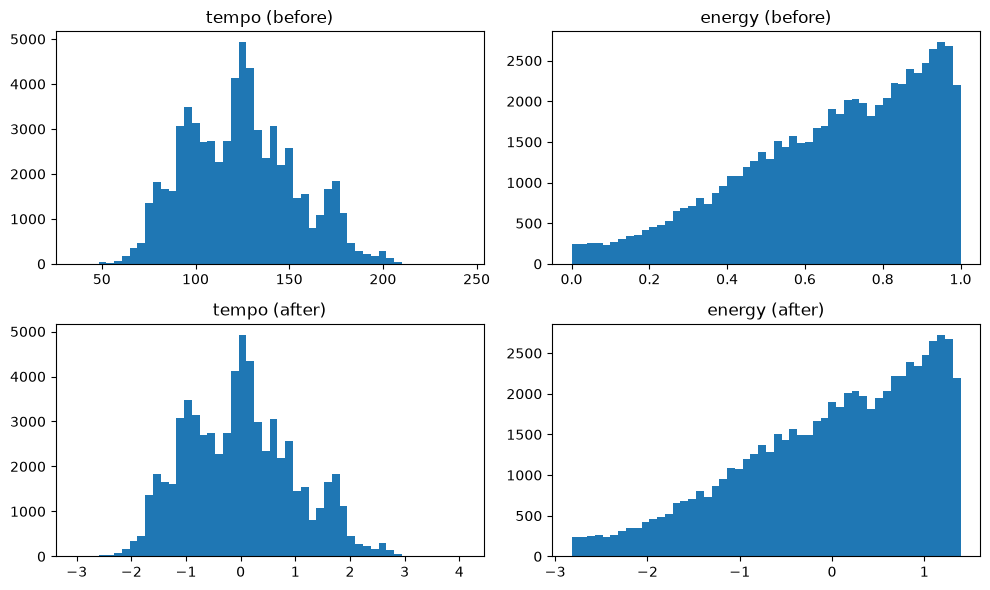

In [9]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(10, 6))

# Before scaling (original values)
axes[0, 0].hist(df["tempo"], bins=50)
axes[0, 0].set_title("tempo (before)")
axes[0, 1].hist(df["energy"], bins=50)
axes[0, 1].set_title("energy (before)")

# After scaling (columns 2 and 1 of X, in FEATURES order)
axes[1, 0].hist(X[:, 2], bins=50)
axes[1, 0].set_title("tempo (after)")
axes[1, 1].hist(X[:, 0], bins=50)
axes[1, 1].set_title("energy (after)")

plt.tight_layout()
plt.show()

2 345195 0.278
3 289737 0.2
4 254704 0.209
5 221759 0.224
6 203255 0.204
7 191940 0.186
8 182870 0.178
9 173745 0.175
10 165635 0.177


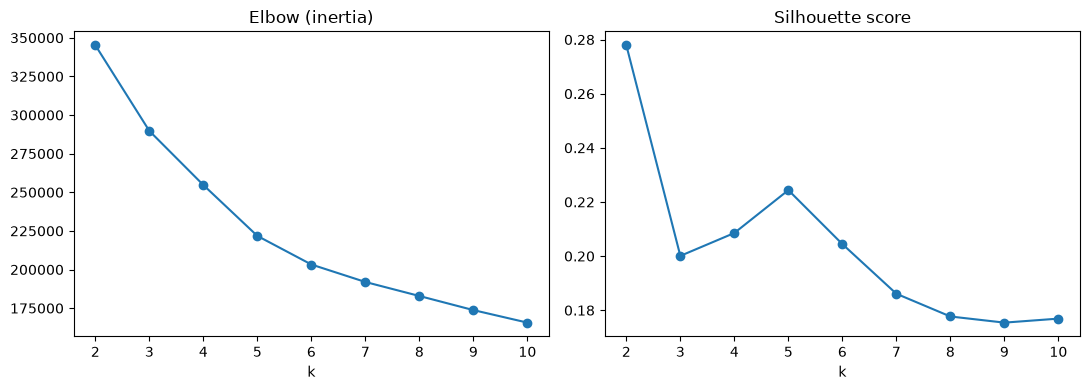

In [10]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

K_RANGE = range(2, 11)
inertias = []
silhouettes = []

for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(X)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X, labels, sample_size=10000, random_state=42))
    print(k, round(inertias[-1]), round(silhouettes[-1], 3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(K_RANGE, inertias, marker="o")
axes[0].set_title("Elbow (inertia)")
axes[0].set_xlabel("k")
axes[1].plot(K_RANGE, silhouettes, marker="o")
axes[1].set_title("Silhouette score")
axes[1].set_xlabel("k")
plt.tight_layout()
plt.show()

In [11]:
from sklearn.cluster import KMeans

# Fit K-Means with k=5 (chosen from the elbow + silhouette scores)
km = KMeans(n_clusters=5, n_init=10, random_state=42)
df["cluster"] = km.fit_predict(X)

# Average feature values per cluster, in original units
profile = df.groupby("cluster")[FEATURES].mean().round(2)
profile["size"] = df["cluster"].value_counts().sort_index()
display(profile)

# 6 random songs per cluster, to sanity-check by ear
for c in range(5):
    print(f"--- cluster {c} ---")
    print(df[df["cluster"] == c][["track_name", "artists", "track_genre"]]
          .sample(6, random_state=1).to_string(index=False))

,energy,valence,tempo,danceability,loudness,acousticness,instrumentalness,size
cluster,,,,,,,,
0,0.18,0.20,108.53,0.39,-20.44,0.86,0.82,3015
1,0.74,0.70,118.42,0.69,-6.33,0.22,0.02,22589
2,0.83,0.37,139.56,0.47,-5.25,0.07,0.03,18040
3,0.41,0.41,114.51,0.55,-10.21,0.64,0.03,14437
4,0.78,0.35,128.81,0.58,-7.92,0.08,0.78,7335


--- cluster 0 ---
                                             track_name                                                              artists    track_genre
                                        Attack on Titan                                                                 Kato          anime
Meditación Budista (Musica de Relajacion para Escuchar)                                                        Reiki Armonía    world-music
                             Interstellar Docking Scene                                                          Eiro Nareth         guitar
              To Zuccabar - From "Gladiator" Soundtrack Hans Zimmer;Djivan Gasparyan;Gavin Greenaway;The Lyndhurst Orchestra         german
                                  Sky Train - Vocal Mix                                                    Omar S;Nite Jewel detroit-techno
                                               Outlined                                                              Spuntic        iranian
--

In [32]:
CLUSTER_NAMES = {
    0: "calm-instrumentals",
    1: "upbeat",
    2: "hype-aggressive",
    3: "chill-laidback",
    4: "intense",
}

# Cluster 0 (calm instrumentals) is excluded since it is not suitable for gym music. The remaining clusters can be used for different workout phases.
PHASE_CLUSTERS = {
    "warmup": [1],
    "peak": [2, 4],
    "cooldown": [3],
}

def phase_bounds(clusters, low=5, high=95):
    sub = df[df["cluster"].isin(clusters)]
    return {f: (sub[f].quantile(low / 100), sub[f].quantile(high / 100))
            for f in FEATURES}

PHASE_BOUNDS = {p: phase_bounds(c) for p, c in PHASE_CLUSTERS.items()}

def fit_plan_to_data(plan):
    """Pull each LLM target into the range of songs that exist for that phase."""
    return {phase: {f: min(max(v, PHASE_BOUNDS[phase][f][0]), PHASE_BOUNDS[phase][f][1])
                    for f, v in vec.items()}
            for phase, vec in plan.items()}

fitted = fit_plan_to_data(plan)
for phase, vec in fitted.items():
    print(phase, {k: round(v, 2) for k, v in vec.items()})
    
df["cluster_name"] = df["cluster"].map(CLUSTER_NAMES)
df["cluster_name"].value_counts()

warmup {'energy': 0.5, 'valence': 0.4, 'danceability': np.float64(0.52), 'acousticness': 0.3, 'instrumentalness': np.float64(0.11), 'tempo': 100.0, 'loudness': np.float64(-10.86)}
peak {'energy': 0.95, 'valence': 0.3, 'danceability': 0.4, 'acousticness': 0.05, 'instrumentalness': 0.1, 'tempo': 115.0, 'loudness': -3.5}
cooldown {'energy': 0.2, 'valence': 0.5, 'danceability': np.float64(0.32), 'acousticness': 0.8, 'instrumentalness': np.float64(0.19), 'tempo': np.float64(75.02), 'loudness': np.float64(-15.74)}


cluster_name
upbeat                22589
hype-aggressive       18040
chill-laidback        14437
intense                7335
calm-instrumentals     3015
Name: count, dtype: int64

In [15]:
import numpy as np
import pandas as pd

# Styles that rarely suit a workout. Edit this list to taste.
GYM_EXCLUDE_GENRES = ["honky-tonk", "bluegrass", "tango", "country", "folk",
                      "gospel", "jazz", "blues", "rockabilly", "classical", "opera"]

def top_matches(target, clusters, n=20, pool_size=60, min_popularity=55,
                exclude_genres=GYM_EXCLUDE_GENRES, seed=None):
    t = scaler.transform(pd.DataFrame([target])[FEATURES])

    # Candidates: right clusters, popular enough, not an excluded genre
    mask = df["cluster"].isin(clusters) & (df["popularity"] >= min_popularity)
    if exclude_genres:
        mask &= ~df["track_genre"].isin(exclude_genres)
    mask = mask.to_numpy()

    # Straight-line distance from the target to each candidate
    dist = np.linalg.norm(X[mask] - t, axis=1)
    out = df[mask].copy()
    out["distance"] = dist

    # Closest first, so the pool really is the closest songs
    out = out.sort_values("distance")
    
    # Take the closest `pool_size` songs, then randomly pick n of them,
    # so each call can give a different playlist
    pool = out.head(pool_size)
    return pool.sample(n=min(n, len(pool)), random_state=seed).sort_values("distance")

peak_target = {"energy": 0.9, "valence": 0.4, "tempo": 135,
               "danceability": 0.55, "loudness": -5,
               "acousticness": 0.1, "instrumentalness": 0.1}

warmup_target = {"energy": 0.6, "valence": 0.6, "tempo": 110,
                 "danceability": 0.65, "loudness": -8,
                 "acousticness": 0.2, "instrumentalness": 0.05}

cooldown_target = {"energy": 0.35, "valence": 0.4, "tempo": 100,
                   "danceability": 0.5, "loudness": -11,
                   "acousticness": 0.6, "instrumentalness": 0.05}

cols = ["track_name", "artists", "track_genre", "energy", "tempo", "distance"]

print("WARMUP")
display(top_matches(warmup_target, PHASE_CLUSTERS["warmup"])[cols])

print("COOLDOWN")
display(top_matches(cooldown_target, PHASE_CLUSTERS["cooldown"])[cols])
result = top_matches(peak_target, PHASE_CLUSTERS["peak"])
result[["track_name", "artists", "track_genre", "energy", "tempo", "distance"]]

WARMUP


,track_name,artists,track_genre,energy,tempo,distance
7611,Yellow Submarine,The Beatles,british,0.636,110.618,0.432259
4652,Mitwa,Shankar-Ehsaan-Loy;Shankar Mahadevan;Caralisa ...,pop-film,0.630,107.103,0.526991
12910,Festa de Maloka,Gabb MC;Caio Passos;Igão;Love Funk;Mc Kadu;MC ...,funk,0.565,119.518,0.538290
3650,Malibu,Virginia To Vegas;NOTD,house,0.653,111.974,0.562508
11082,Ambikapathy,A.R. Rahman;Naresh Iyer,pop-film,0.702,113.006,0.576488
9527,Nee Paata Madhuram - The Touch of Love,Anirudh Ravichander;Roop Kumar Rathod;Shreya G...,hip-hop,0.570,110.061,0.599152
2878,134340,BTS,k-pop,0.687,106.023,0.609731
5752,Good Times Roll,The Cars,power-pop,0.662,107.643,0.638696
12005,Penny Lane - Remastered 2015,The Beatles,psych-rock,0.592,113.265,0.650196
524,Cigarettes out the Window,TV Girl,indie-pop,0.659,113.551,0.689773


COOLDOWN


,track_name,artists,track_genre,energy,tempo,distance
5760,World Spins Madly On,The Weepies;Deb Talan;Steve Tannen,acoustic,0.311,107.612,0.655680
3243,Just Breathe,Pearl Jam,grunge,0.348,107.819,0.696999
4603,Babooshka - 2018 Remaster,Kate Bush,piano,0.362,108.866,0.792914
795,Dust in the Wind,Kansas,hard-rock,0.322,93.503,0.822118
7356,Yamma Yamma,Harris Jayaraj;S. P. Balasubrahmanyam,pop-film,0.431,88.809,0.833272
12996,Glory (feat. Ladysmith Black Mambazo),Burna Boy;Ladysmith Black Mambazo,dancehall,0.416,85.115,0.868618
5975,Aisay Kaisay,Hasan Raheem;Abdullah Kasumbi,indie-pop,0.428,104.938,0.874240
12762,A Day In The Life,Wes Montgomery,guitar,0.364,98.445,0.877947
8590,Stand By Me,Skylar Grey,piano,0.333,107.969,0.880236
4996,Home Again,Michael Kiwanuka,british,0.320,85.891,0.912819


,track_name,artists,track_genre,energy,tempo,distance
3387,Your Betrayal,Bullet For My Valentine,metal,0.883,134.001,0.513184
13071,Rapture - Avicii New Generation Mix,Nadia Ali,trance,0.934,130.008,0.551597
888,Memories (feat. Kid Cudi),David Guetta;Kid Cudi,edm,0.916,129.983,0.561208
3029,Not In The Mood (feat. Fivio Foreign & Kay Flock),Lil Tjay;Fivio Foreign;Kay Flock,r-n-b,0.820,141.908,0.570328
2735,A Place for My Head,Linkin Park,alternative,0.908,133.063,0.593636
1365,Drunk-Dazed,ENHYPEN,anime,0.869,132.889,0.609096
11423,Diamond is unbreakable - Main Theme,Yugo Kanno,anime,0.897,129.929,0.613837
3658,Ilahi,Pritam;Arijit Singh,indian,0.967,131.988,0.623918
11312,Wasted Nights,ONE OK ROCK,emo,0.833,125.070,0.630007
11889,EVERBLUE,Omoinotake,j-pop,0.895,134.985,0.635355


In [14]:
for pop in [30, 40, 55]:
    for pool in [30, 60, 100]:
        r = top_matches(peak_target, PHASE_CLUSTERS["peak"],
                        pool_size=pool, min_popularity=pop, seed=1)
        print(f"popularity>={pop}  pool={pool}  "
              f"avg distance={r['distance'].mean():.2f}  "
              f"avg popularity={r['popularity'].mean():.0f}")

popularity>=30  pool=30  avg distance=0.52  avg popularity=50
popularity>=30  pool=60  avg distance=0.57  avg popularity=52
popularity>=30  pool=100  avg distance=0.60  avg popularity=48
popularity>=40  pool=30  avg distance=0.54  avg popularity=57
popularity>=40  pool=60  avg distance=0.59  avg popularity=58
popularity>=40  pool=100  avg distance=0.62  avg popularity=57
popularity>=55  pool=30  avg distance=0.59  avg popularity=64
popularity>=55  pool=60  avg distance=0.63  avg popularity=63
popularity>=55  pool=100  avg distance=0.67  avg popularity=63


In [16]:
all_clusters = [1, 2, 3, 4]  # everything except the ambient cluster 0

for name, target in [("warmup", warmup_target),
                     ("peak", peak_target),
                     ("cooldown", cooldown_target)]:
    for label, cl in [("phase clusters", PHASE_CLUSTERS[name]),
                      ("all clusters", all_clusters)]:
        r = top_matches(target, cl, seed=1)
        print(f"{name:9} {label:15} avg distance={r['distance'].mean():.2f}")

warmup    phase clusters  avg distance=0.69
warmup    all clusters    avg distance=0.69
peak      phase clusters  avg distance=0.63
peak      all clusters    avg distance=0.63
cooldown  phase clusters  avg distance=0.90
cooldown  all clusters    avg distance=0.90


13 tracks, 46.0 min
phase
cooldown    1.56
peak        0.74
warmup      1.32
Name: distance, dtype: float64


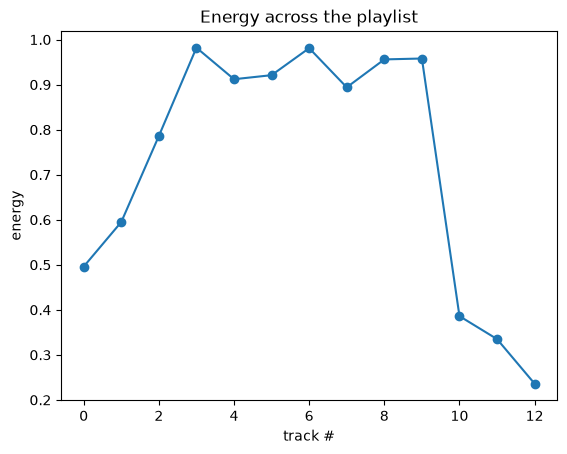

In [34]:
import matplotlib.pyplot as plt

def fill_phase(target, clusters, budget_ms, used_ids, artist_counts,
               max_per_artist=2, tolerance_ms=60_000, seed=None):
    # n == pool_size, so this returns the whole pool of closest matches
    pool = top_matches(target, clusters, n=60, pool_size=60, seed=seed)
    pool = pool.sample(frac=1, random_state=seed)  # shuffle for variety

    chosen, total = [], 0
    for _, row in pool.iterrows():
        if total >= budget_ms:
            break
        artist = row["main_artist"]
        if row["track_id"] in used_ids or artist_counts.get(artist, 0) >= max_per_artist:
            continue
        # Skip songs that would push this phase well past its time budget
        if total + row["duration_ms"] > budget_ms + tolerance_ms:
            continue
        chosen.append(row)
        total += row["duration_ms"]
        used_ids.add(row["track_id"])
        artist_counts[artist] = artist_counts.get(artist, 0) + 1
    return pd.DataFrame(chosen)


def build_playlist(plan, duration_min=45, seed=None):
    total_ms = duration_min * 60_000
    used_ids, artist_counts = set(), {}

    warmup = fill_phase(plan["warmup"], PHASE_CLUSTERS["warmup"], 0.2 * total_ms,
                        used_ids, artist_counts, seed=seed)
    peak = fill_phase(plan["peak"], PHASE_CLUSTERS["peak"], 0.6 * total_ms,
                      used_ids, artist_counts, seed=seed)
    cooldown = fill_phase(plan["cooldown"], PHASE_CLUSTERS["cooldown"], 0.2 * total_ms,
                          used_ids, artist_counts, seed=seed)

    warmup = warmup.sort_values("energy").assign(phase="warmup")
    peak = peak.assign(phase="peak")
    cooldown = cooldown.sort_values("energy", ascending=False).assign(phase="cooldown")
    return pd.concat([warmup, peak, cooldown], ignore_index=True)


pl = build_playlist(fitted, 45, seed=1)
print(f"{len(pl)} tracks, {pl['duration_ms'].sum() / 60_000:.1f} min")
print(pl.groupby("phase")["distance"].mean().round(2))

plt.plot(pl["energy"].values, marker="o")
plt.title("Energy across the playlist")
plt.xlabel("track #"); plt.ylabel("energy")
plt.show()

In [35]:
import os, json
from dotenv import load_dotenv
from google import genai
from google.genai import types
from pydantic import BaseModel
import time

load_dotenv()
client = genai.Client(api_key=os.environ["GEMINI_API_KEY"])

# The shape the LLM must return
class PhaseTarget(BaseModel):
    energy: float
    valence: float
    tempo: float
    danceability: float
    loudness: float
    acousticness: float
    instrumentalness: float

class MoodPlan(BaseModel):
    warmup: PhaseTarget
    peak: PhaseTarget
    cooldown: PhaseTarget

# Used if the LLM call fails
DEFAULT_PLAN = {"warmup": warmup_target, "peak": peak_target, "cooldown": cooldown_target}

# Valid ranges, used to clamp anything the LLM gets wrong
BOUNDS = {"energy": (0, 1), "valence": (0, 1), "danceability": (0, 1),
          "acousticness": (0, 1), "instrumentalness": (0, 1),
          "tempo": (60, 200), "loudness": (-20, -2)}

# Typical song profile per phase, computed from the actual data
phase_profiles = {
    p: df[df["cluster"].isin(c)][FEATURES].median().round(2).to_dict()
    for p, c in PHASE_CLUSTERS.items()
}
print(phase_profiles)

SYSTEM_PROMPT = f"""You design workout playlists. Given a description of a gym session
and the user's mood, output target audio features for three phases:
warmup (first ~20%), peak (middle ~60%), cooldown (last ~20%).

Feature ranges:
- energy, valence, danceability, acousticness, instrumentalness: 0.0 to 1.0
- tempo: beats per minute
- loudness: decibels, negative (quieter is lower)

The song library only contains songs like these typical profiles (median values):
warmup: {phase_profiles['warmup']}
peak: {phase_profiles['peak']}
cooldown: {phase_profiles['cooldown']}

Start from these profiles and adjust to fit the user's request. Shift energy,
valence, danceability, acousticness and instrumentalness by at most about 0.15,
tempo by at most about 15 BPM, and loudness by at most about 3 dB. Do not go
far outside these profiles, because no songs exist there.
Warmup is moderate, peak is the most intense, cooldown is the calmest.
Cardio suits higher tempo; heavy lifting suits lower tempo with high energy."""

_cache.clear()  # old cached plans came from the old prompt

_cache = {}

def clamp_plan(plan):
    out = {}
    for phase in ["warmup", "peak", "cooldown"]:
        out[phase] = {f: min(max(float(plan[phase][f]), lo), hi)
                      for f, (lo, hi) in BOUNDS.items()}
    return out

# Tried in order; if one is overloaded or unavailable, move to the next
MODELS = ["gemini-3.5-flash-lite", "gemini-3.7-flash", "gemini-3.8-flash"]

def parse_mood(text, retries_per_model=2):
    if text in _cache:
        return _cache[text]

    for model in MODELS:
        for attempt in range(retries_per_model):
            try:
                resp = client.models.generate_content(
                    model=model,
                    contents=text,
                    config=types.GenerateContentConfig(
                        system_instruction=SYSTEM_PROMPT,
                        response_mime_type="application/json",
                        response_schema=MoodPlan,
                        temperature=0.3,
                    ),
                )
                plan = clamp_plan(json.loads(resp.text))
                _cache[text] = plan
                print(f"(used {model})")
                return plan
            except Exception as e:
                print(f"{model} attempt {attempt + 1} failed: {str(e)[:120]}")
                time.sleep(2 * (attempt + 1))  # wait a bit longer each retry

    print("All models failed, using default targets")
    return DEFAULT_PLAN  # not cached, so the next call retries

plan = parse_mood("feeling sluggish but need to hit a heavy leg day")
for phase, vec in plan.items():
    print(phase, {k: round(v, 2) for k, v in vec.items()})


{'warmup': {'energy': 0.75, 'valence': 0.72, 'tempo': 118.19, 'danceability': 0.69, 'loudness': -6.03, 'acousticness': 0.15, 'instrumentalness': 0.0}, 'peak': {'energy': 0.86, 'valence': 0.34, 'tempo': 135.01, 'danceability': 0.5, 'loudness': -5.56, 'acousticness': 0.01, 'instrumentalness': 0.0}, 'cooldown': {'energy': 0.42, 'valence': 0.38, 'tempo': 113.64, 'danceability': 0.55, 'loudness': -9.81, 'acousticness': 0.69, 'instrumentalness': 0.0}}
(used gemini-3.5-flash-lite)
warmup {'energy': 0.7, 'valence': 0.65, 'danceability': 0.65, 'acousticness': 0.2, 'instrumentalness': 0.0, 'tempo': 110.0, 'loudness': -6.5}
peak {'energy': 0.9, 'valence': 0.3, 'danceability': 0.45, 'acousticness': 0.01, 'instrumentalness': 0.0, 'tempo': 120.0, 'loudness': -5.0}
cooldown {'energy': 0.35, 'valence': 0.35, 'danceability': 0.5, 'acousticness': 0.75, 'instrumentalness': 0.0, 'tempo': 105.0, 'loudness': -10.5}


In [36]:
plan = parse_mood("feeling sluggish but need to hit a heavy leg day")
fitted = fit_plan_to_data(plan)
pl = build_playlist(fitted, 45, seed=1)
print(f"{len(pl)} tracks, {pl['duration_ms'].sum() / 60_000:.1f} min")
print(pl.groupby("phase")["distance"].mean().round(2))

for txt in ["5k run, want to feel pumped",
            "light mobility and stretching day, relaxed"]:
    p = fit_plan_to_data(parse_mood(txt))
    print(txt)
    for phase, vec in p.items():
        print(" ", phase, {k: round(v, 2) for k, v in vec.items()})

12 tracks, 47.2 min
phase
cooldown    0.86
peak        0.57
warmup      0.64
Name: distance, dtype: float64
(used gemini-3.5-flash-lite)
5k run, want to feel pumped
  warmup {'energy': 0.8, 'valence': 0.8, 'danceability': 0.72, 'acousticness': 0.1, 'instrumentalness': 0.0, 'tempo': 125.0, 'loudness': -5.5}
  peak {'energy': 0.95, 'valence': 0.45, 'danceability': 0.55, 'acousticness': np.float64(0.0), 'instrumentalness': 0.0, 'tempo': 145.0, 'loudness': -4.5}
  cooldown {'energy': 0.45, 'valence': 0.4, 'danceability': 0.5, 'acousticness': 0.7, 'instrumentalness': 0.0, 'tempo': 110.0, 'loudness': -9.0}
(used gemini-3.5-flash-lite)
light mobility and stretching day, relaxed
  warmup {'energy': 0.65, 'valence': 0.62, 'danceability': 0.6, 'acousticness': 0.3, 'instrumentalness': 0.05, 'tempo': 110.0, 'loudness': -7.0}
  peak {'energy': 0.72, 'valence': 0.45, 'danceability': 0.52, 'acousticness': 0.15, 'instrumentalness': 0.02, 'tempo': 120.0, 'loudness': -6.5}
  cooldown {'energy': 0.35, 'v